Practical 6 :Analytics on Time Series Data

Name - Kimi Patle
Roll No. - 7

<Axes: xlabel='DATE'>

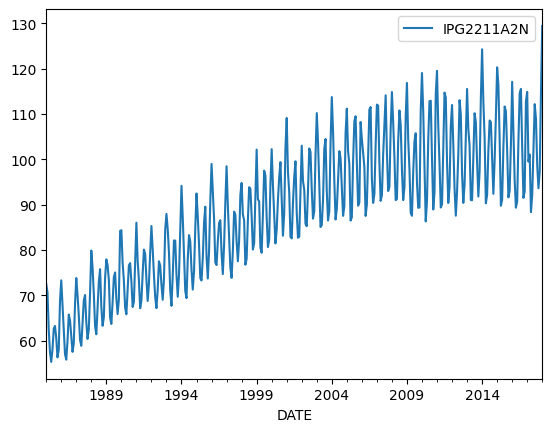

In [16]:
import pandas as pd
import matplotlib
from statsmodels.tsa.seasonal import seasonal_decompose
import matplotlib.pyplot as plt
data = pd.read_csv("Electric_Production.csv")
data['DATE'] = pd.to_datetime(data['DATE'])
data = data.set_index('DATE')
data.plot()

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [18]:
np.random.seed(0)
date_rng = pd.date_range(start="2021-01-01", periods=365, freq="D")
data = np.sin(np.arange(365) * 2 * np.pi / 365) + np.random.normal(0, 0.5, 365)
ts = pd.Series(data, index=date_rng)

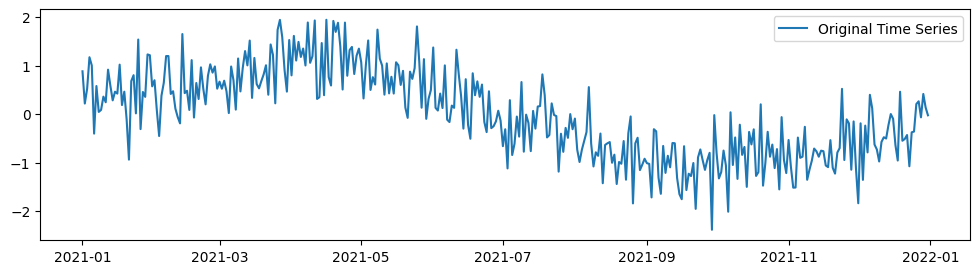

In [19]:
plt.figure(figsize=(12, 3))
plt.plot(ts, label='Original Time Series')
plt.legend()

In [20]:
result_add = seasonal_decompose(ts, model='additive')

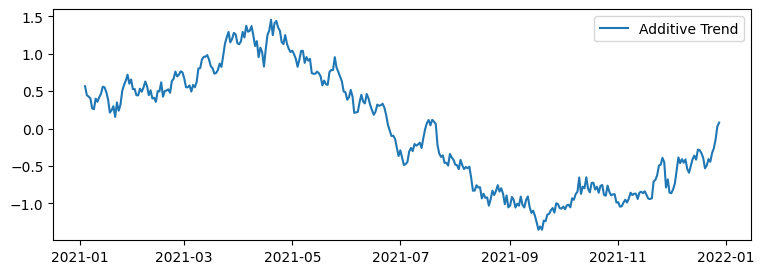

In [21]:
plt.figure(figsize=(9, 3))
plt.plot(result_add.trend, label='Additive Trend')
plt.legend()

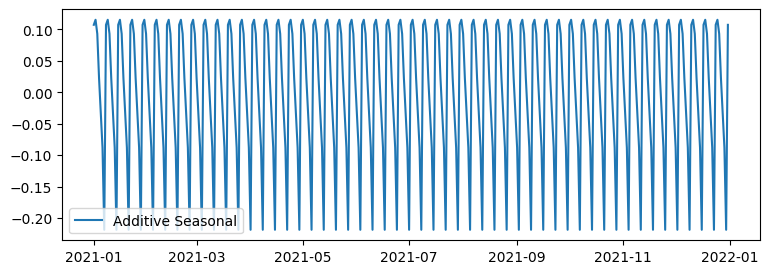

In [22]:
plt.figure(figsize=(9, 3))
plt.plot(result_add.seasonal, label='Additive Seasonal')
plt.legend()

In [23]:
sma_window = 7
sma = ts.rolling(window=sma_window).mean()
sma

,0
2021-01-01,NaN
2021-01-02,NaN
2021-01-03,NaN
2021-01-04,NaN
2021-01-05,NaN
...,...
2021-12-27,-0.326866
2021-12-28,-0.262944
2021-12-29,-0.142060
2021-12-30,0.030998


In [25]:
ema_window = 7
ema = ts.ewm(span=ema_window, adjust=False).mean()
ema

,0
2021-01-01,0.882026
2021-01-02,0.715843
2021-01-03,0.667830
2021-01-04,0.793889
2021-01-05,0.846062
...,...
2021-12-27,-0.165240
2021-12-28,-0.140660
2021-12-29,-0.001919
2021-12-30,0.032451


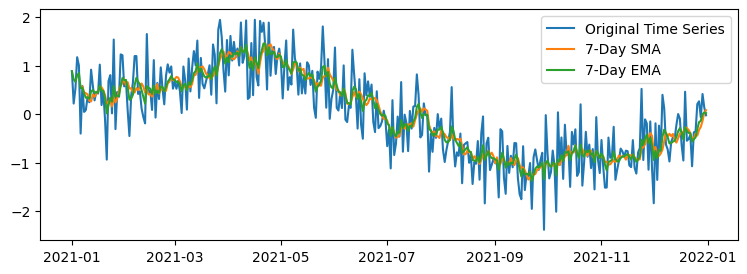

In [26]:
plt.figure(figsize=(9, 3))
plt.plot(ts, label='Original Time Series')
plt.plot(sma, label=f'{sma_window}-Day SMA')
plt.plot(ema, label=f'{ema_window}-Day EMA')
plt.legend()

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import warnings
import itertools
warnings.filterwarnings('ignore')

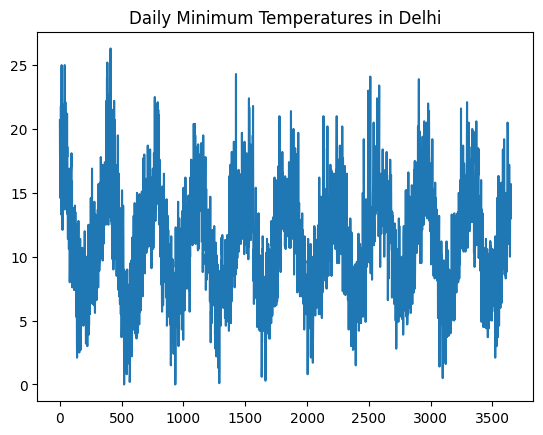

In [29]:
data = pd.read_csv('/content/daily-min-temperatures.csv')
data['Temp'] = pd.to_numeric(data['Temp'], errors='coerce')
ts = data['Temp']

ts.plot(title='Daily Minimum Temperatures in Delhi')
plt.show()

In [32]:
# Grid search to find the best ARIMA parameters (p, d, q) based on AIC
p_values = range(0, 3)
d_values = range(0, 2)
q_values = range(0, 3)

best_score, best_order = float("inf"), None

for p in p_values:
    for d in d_values:
        for q in q_values:
            order = (p, d, q)
            try:
                model = ARIMA(ts.dropna(), order=order)
                results_temp = model.fit()
                aic = results_temp.aic
                if aic < best_score:
                    best_score, best_order = aic, order
            except:
                continue

print(f'Best ARIMA Order: {best_order} with AIC: {best_score}')

Best ARIMA Order: (2, 1, 1) with AIC: 16780.78531802406


In [33]:
final_model = ARIMA(ts, order=best_order)
results = final_model.fit()
forecast_values = results.forecast(steps=10)

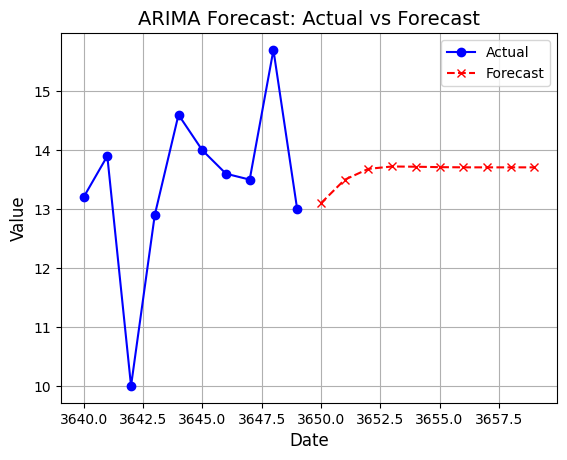

In [34]:
plt.plot(ts[-10:].index, ts[-10:], label='Actual', color='blue', linestyle='-', marker='o')
plt.plot(forecast_values.index, forecast_values, label='Forecast', color='red', linestyle='--',
marker='x')
plt.title('ARIMA Forecast: Actual vs Forecast', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Value', fontsize=12)
plt.legend()

plt.grid(True)
plt.show()

**Assignment Questions**



Creates monthly sales time-series data,Displays the original time series,Performs trend
analysis,Calculates a 3-month moving average.

• Applies exponential smoothing.

• Performs time-series decomposition
into trend, seasonal, and residual
components.

• Builds an ARIMA(1,1,1) model.

• Forecasts the next 3 months.

• Displays the forecast graphically.

---



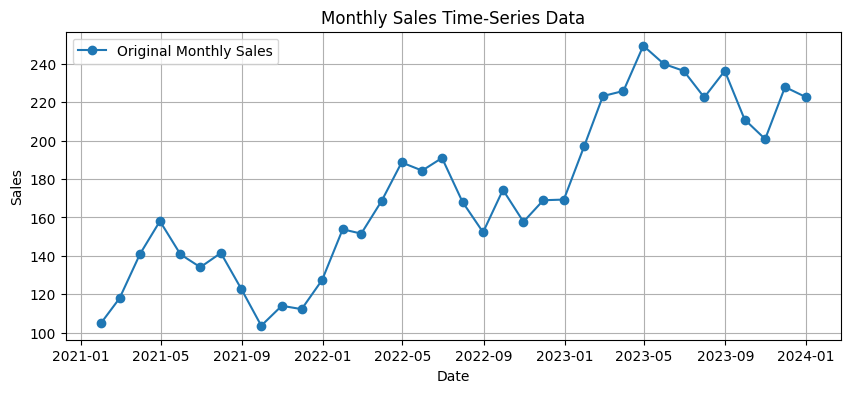

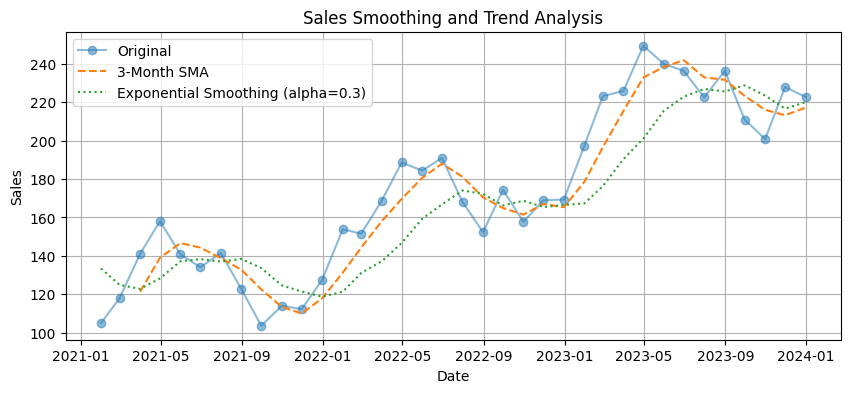

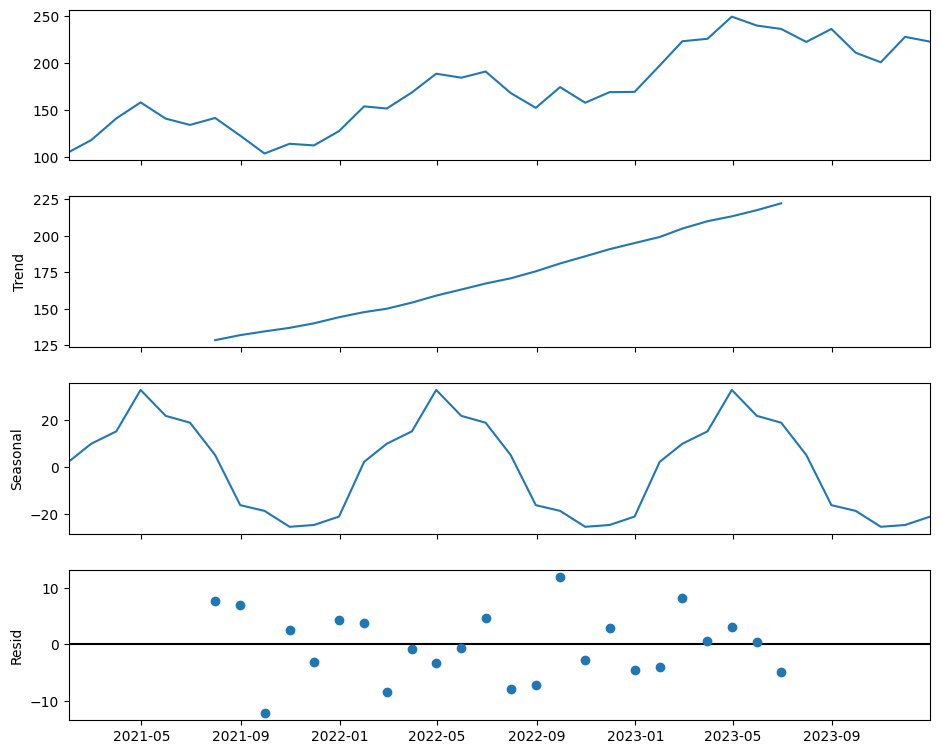

In [54]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.api import SimpleExpSmoothing
from statsmodels.tsa.arima.model import ARIMA

# 1. Create monthly sales time-series data (3 years: 36 months)
np.random.seed(42)
months = pd.date_range(start="2021-01-01", periods=36, freq="M")
# Trend + Seasonality + Noise
trend = np.linspace(100, 250, 36)
seasonality = 30 * np.sin(np.arange(36) * 2 * np.pi / 12)
noise = np.random.normal(0, 10, 36)
sales_data = trend + seasonality + noise
sales_ts = pd.Series(sales_data, index=months)

# 2. Display the original time series
plt.figure(figsize=(10, 4))
plt.plot(sales_ts, marker='o', label='Original Monthly Sales')
plt.title('Monthly Sales Time-Series Data')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.grid(True)
plt.show()

# 3. Trend analysis & 4. Calculate a 3-month moving average
sales_sma_3 = sales_ts.rolling(window=3).mean()

# 5. Apply exponential smoothing (fixing initialization_method for statsmodels compatibility)
ema_model = SimpleExpSmoothing(sales_ts, initialization_method='estimated').fit(smoothing_level=0.3, optimized=False)
sales_ema = ema_model.fittedvalues

# Plot Moving Average and Exponential Smoothing
plt.figure(figsize=(10, 4))
plt.plot(sales_ts, marker='o', alpha=0.5, label='Original')
plt.plot(sales_sma_3, label='3-Month SMA', linestyle='--')
plt.plot(sales_ema, label='Exponential Smoothing (alpha=0.3)', linestyle=':')
plt.title('Sales Smoothing and Trend Analysis')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.grid(True)
plt.show()

# 6. Time-series decomposition
decomp = seasonal_decompose(sales_ts, model='additive')
fig = decomp.plot()
fig.set_size_inches(10, 8)
plt.show()



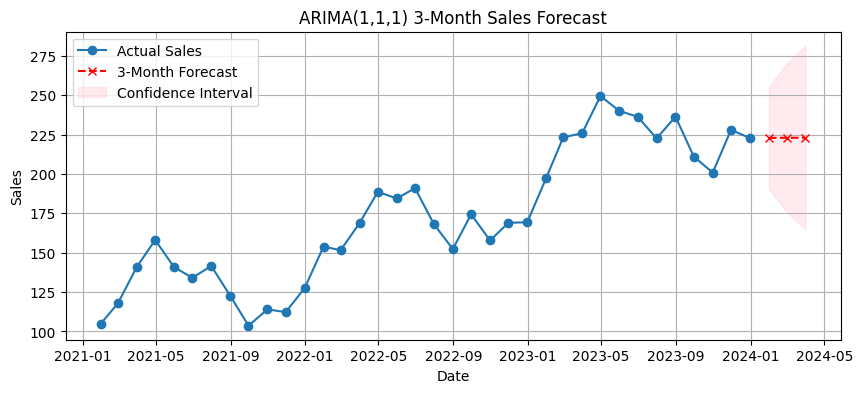

In [55]:
 #7. Build ARIMA(1,1,1) model
arima_model = ARIMA(sales_ts, order=(1, 1, 1))
arima_result = arima_model.fit()

# 8. Forecast the next 3 months
forecast_steps = 3
forecast_res = arima_result.get_forecast(steps=forecast_steps)
forecast_mean = forecast_res.predicted_mean
confidence_intervals = forecast_res.conf_int()

# 9. Display the forecast graphically
plt.figure(figsize=(10, 4))
plt.plot(sales_ts, marker='o', label='Actual Sales')
plt.plot(forecast_mean, marker='x', color='red', linestyle='--', label='3-Month Forecast')
plt.fill_between(confidence_intervals.index,
                 confidence_intervals.iloc[:, 0],
                 confidence_intervals.iloc[:, 1],
                 color='pink', alpha=0.3, label='Confidence Interval')
plt.title('ARIMA(1,1,1) 3-Month Sales Forecast')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.grid(True)
plt.show()